# DINO for Image Segmentation

Author: Porter Rigby

*Based on Caron et al., "Emerging Properties in Self-Supervised Vision Transformers", ICCV 2021.*

Companion notebook for the blog post *DINO for Image Segmentation*. It reproduces every result figure and table in the post; each section says which one it produces. No model is trained; all weights are pretrained.

## 0. Setup

**Requirements:** `torch`, `torchvision`, `matplotlib`, `numpy`, `scikit-image`. A GPU is optional; every step also runs on CPU, just slower.

In [1]:
import os, random
import numpy as np
import torch
import torch.nn.functional as F
import torchvision
from torchvision import transforms as T
from torchvision.datasets import OxfordIIITPet
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Reproducibility
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# "cuda" also covers AMD GPUs when PyTorch is built with ROCm
device = "cuda" if torch.cuda.is_available() else "cpu"

IMG_SIZE = 224           # every image is resized to 224x224
FIG_DIR, DATA_DIR = "figures", "data"
os.makedirs(FIG_DIR, exist_ok=True)

# Attention-mass thresholds we try when turning attention into a mask
THRESHOLDS = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

# ImageNet normalization (used by both DINO and the supervised ViT)
MEAN = torch.tensor([0.485, 0.456, 0.406])
STD = torch.tensor([0.229, 0.224, 0.225])

# Plot style: light grid, one fixed color per model
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.titlesize": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "grid.color": "#e4e3df", "grid.linewidth": 0.8})
TEXT_MUTED = "#52514e"
print(f"torch {torch.__version__} | torchvision {torchvision.__version__} | "
      f"device: {device}")

torch 2.14.1+rocm7.14 | torchvision 0.29.1+rocm7.14 | device: cuda


## 1. Load the models

*Blog: the **Models** paragraph.*

* **DINO** models come from the authors' official repository via `torch.hub`. The name `vits8` means *ViT-Small with 8x8-pixel patches*.
* The **supervised** baseline is torchvision's ViT-B/16 trained on ImageNet labels. It has exactly the same architecture as `DINO ViT-B/16`, so any difference between the two comes from **how they were trained**.

torchvision's ViT does not return its attention weights. The small wrapper below recomputes them for the last block so both model types share one interface.

In [2]:
def load_dino(name):
    # trust_repo=True: we knowingly load code from the official facebookresearch/dino repo
    model = torch.hub.load("facebookresearch/dino:main", name, trust_repo=True)
    return model.eval().to(device)


class SupervisedViT:
    # Wraps torchvision's supervised ViT-B/16 so it has the same methods as DINO models.
    patch_size = 16

    def __init__(self):
        weights = torchvision.models.ViT_B_16_Weights.IMAGENET1K_V1
        self.net = torchvision.models.vit_b_16(weights=weights).eval().to(device)
        self.last_block = self.net.encoder.layers[-1]
        self._cache = {}
        # forward hooks run automatically during self.net(x)
        # and store intermediate outputs:
        # (a) normalized input to the last attention layer, (b) final token features
        self.last_block.ln_1.register_forward_hook(
            lambda m, i, o: self._cache.__setitem__("ln1", o))
        self.net.encoder.register_forward_hook(
            lambda m, i, o: self._cache.__setitem__("tokens", o))

    @torch.no_grad()
    def get_last_selfattention(self, x):
        self.net(x)
        y = self._cache["ln1"]
        _, attn = self.last_block.self_attention(y, y, y, need_weights=True,
                                                 average_attn_weights=False)
        return attn                                     # [B, heads, tokens, tokens]

    @torch.no_grad()
    def patch_features(self, x):
        self.net(x)
        return self._cache["tokens"][:, 1:]             # drop the [CLS] token


models = {
    "DINO ViT-S/16": load_dino("dino_vits16"),
    "DINO ViT-S/8": load_dino("dino_vits8"),
    "DINO ViT-B/16": load_dino("dino_vitb16"),
    "Supervised ViT-B/16": SupervisedViT(),
}
# One fixed color per model, used in every chart
COLORS = {"DINO ViT-S/16": "#2a78d6", "DINO ViT-S/8": "#eb6834",
          "DINO ViT-B/16": "#1baf7a", "Supervised ViT-B/16": "#eda100"}
BASELINE_COLOR = "#8a8984"

Using cache found in /home/prigby/.cache/torch/hub/facebookresearch_dino_main
Using cache found in /home/prigby/.cache/torch/hub/facebookresearch_dino_main
Using cache found in /home/prigby/.cache/torch/hub/facebookresearch_dino_main


### Helper functions

The last-layer attention from the **[CLS] token** to every patch, reshaped into a 2D map (one per head), is what we threshold into a mask.

In [3]:
def patch_size(model):
    if isinstance(model, SupervisedViT):
        return model.patch_size
    return model.patch_embed.patch_size


@torch.no_grad()
def cls_attention(model, x):
    # Last-layer attention from the [CLS] token to every patch: [B, heads, h, w]
    attn = model.get_last_selfattention(x)          # [B, heads, 1 + h*w, 1 + h*w]
    h = w = x.shape[-1] // patch_size(model)
    return attn[:, :, 0, 1:].reshape(x.shape[0], -1, h, w)


@torch.no_grad()
def patch_features(model, x):
    # Output feature vector of every patch token: [B, h*w, dim]
    if isinstance(model, SupervisedViT):
        return model.patch_features(x)
    return model.get_intermediate_layers(x, n=1)[0][:, 1:]


def attention_to_mask(attn, threshold=0.6):
    # Paper recipe, applied to each head separately: the mask is the smallest set of
    # patches that together hold `threshold` of that head's attention mass.
    flat = attn.flatten(-2)
    flat = flat / flat.sum(-1, keepdim=True)
    vals, idx = flat.sort(-1, descending=True)
    cum = vals.cumsum(-1)
    in_mask = (cum - vals) < threshold    # also include the patch that crosses it
    mask = torch.zeros_like(flat, dtype=torch.bool).scatter(-1, idx, in_mask)
    return mask.reshape(attn.shape)


def upsample(m, size=IMG_SIZE, mode="nearest"):
    # Patch-level map [B, C, h, w] -> pixel-level map [B, C, size, size]
    out = F.interpolate(m.float(), size=(size, size), mode=mode)
    return out.bool() if m.dtype == torch.bool else out


def iou(pred, fg, ignore):
    # Intersection-over-Union per image, skipping 'ignore' pixels (the trimap border)
    valid = ~ignore
    inter = (pred & fg & valid).sum((-2, -1)).float()
    union = ((pred | fg) & valid).sum((-2, -1)).float()
    return inter / union.clamp(min=1)


@torch.no_grad()
def per_head_iou(model, loader, thresholds=(0.6,)):
    # Threshold every head separately (paper recipe) and score it.
    # Returns {threshold: array [N_images, heads]} of per-image, per-head IoU.
    out = {t: [] for t in thresholds}
    for x, tri in loader:
        x, tri = x.to(device), tri.to(device)
        fg, ign = (tri == 1), (tri == 3)         # [B, 1, H, W]; border (3) ignored
        attn = cls_attention(model, x)                   # computed once per batch
        for t in thresholds:
            masks = upsample(attention_to_mask(attn, t)) # [B, heads, H, W]: mask per head
            out[t].append(iou(masks, fg, ign).cpu())     # [B, heads]
    return {t: torch.cat(v).numpy() for t, v in out.items()}


def to_display(x):
    # Undo the normalization so a tensor image can be shown with imshow
    img = x.cpu() * STD[:, None, None] + MEAN[:, None, None]
    return img.clamp(0, 1).permute(1, 2, 0).numpy()


def heat(a):
    # Upsample a single [h, w] attention map smoothly and rescale to [0, 1] for display
    a = upsample(a[None, None], mode="bilinear")[0, 0]
    return ((a - a.min()) / (a.max() - a.min() + 1e-8)).cpu().numpy()


RED = ListedColormap(["#e34948"])
def show(ax, img, heatmap=None, mask=None, gt=None, title=""):
    ax.imshow(img)
    if heatmap is not None:
        ax.imshow(heatmap, cmap="inferno", alpha=0.65)
    if mask is not None:
        ax.imshow(np.ma.masked_where(~mask, mask.astype(float)), cmap=RED, alpha=0.5,
                  vmin=0, vmax=1)
    if gt is not None:
        ax.contour(gt, levels=[0.5], colors="#00e5ff", linewidths=1.2)
    ax.set_title(title); ax.axis("off")


def row_label(ax, text):
    # Label a row of image panels on its left, without drawing an axis frame
    ax.axis("on"); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_ylabel(text, fontsize=9)

## 2. Data: Oxford-IIIT Pet

*Blog: the **Data** paragraph.*

Photos of 37 cat and dog breeds, each with a trimap labeling every pixel *pet* (1), *background* (2) or *border* (3); border pixels are ignored when scoring. We choose the head and threshold on 300 random **trainval** images and report results on 500 random **test** images. All images are resized to 224x224.

In [4]:
img_tf = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), T.Normalize(MEAN, STD)])
mask_tf = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE),
                              interpolation=T.InterpolationMode.NEAREST),
                     T.PILToTensor()])

pets = OxfordIIITPet(DATA_DIR, split="test", target_types="segmentation", download=True,
                     transform=img_tf, target_transform=mask_tf)
pets_trainval = OxfordIIITPet(DATA_DIR, split="trainval", target_types="segmentation",
                              download=True, transform=img_tf, target_transform=mask_tf)
print(f"Test images: {len(pets)} | trainval images: {len(pets_trainval)}")

# Random subsets (fixed seeds, so results are reproducible)
N_EVAL, N_SELECT = 500, 300
eval_idx = np.random.default_rng(SEED).choice(len(pets), N_EVAL, replace=False)
select_idx = np.random.default_rng(SEED + 1).choice(len(pets_trainval), N_SELECT,
                                                    replace=False)
# test images (evaluation) and trainval images (selection)
loader = DataLoader(Subset(pets, eval_idx), batch_size=32, num_workers=4)
select_loader = DataLoader(Subset(pets_trainval, select_idx), batch_size=32,
                           num_workers=4)

def get_pet(i):
    # Test image i -> (normalized image [1,3,H,W] on device,
    #                  foreground mask [H,W], ignore mask [H,W])
    x, tri = pets[int(i)]
    return x[None].to(device), (tri[0] == 1), (tri[0] == 3)

Test images: 3669 | trainval images: 3680


## 3. Choosing a head and a threshold (trainval)

*Blog: the **Choosing a head and a threshold** paragraph; the chosen heads in Table 1.*

For each model we score every head at every threshold in `THRESHOLDS` on the 300 trainval images and pick the (head, threshold) pair with the highest mean IoU. That choice is frozen before any test image is scored.

In [5]:
BEST_HEAD, BEST_THRESHOLD, select_iou = {}, {}, {}
print(f"Chosen on {N_SELECT} trainval images (selection set):")
print(f"{'Model':<22}{'Heads':>6}{'Chosen head':>13}{'Chosen threshold':>18}"
      f"{'Selection IoU':>15}")
for name, model in models.items():
    sel = per_head_iou(model, select_loader, THRESHOLDS)  # {threshold: [N_SELECT, heads]}
    grid = np.stack([sel[t].mean(0) for t in THRESHOLDS]) # [thresholds, heads] mean IoU
    ti, h = np.unravel_index(grid.argmax(), grid.shape)
    BEST_THRESHOLD[name], BEST_HEAD[name] = THRESHOLDS[ti], int(h)
    select_iou[name] = grid[ti, h]
    print(f"{name:<22}{grid.shape[1]:>6}{BEST_HEAD[name]:>13}"
          f"{BEST_THRESHOLD[name]:>18.1f}{select_iou[name]:>15.3f}")

Chosen on 300 trainval images (selection set):
Model                  Heads  Chosen head  Chosen threshold  Selection IoU


MIOpen(HIP): Warning [ParseAndLoadDb] File is unreadable: "/home/prigby/School/computer_vision/.venv/lib/python3.13/site-packages/_rocm_sdk_libraries/share/miopen/db/gfx1100_48.HIP.fdb.txt"


DINO ViT-S/16              6            1               0.9          0.756
DINO ViT-S/8               6            2               0.9          0.752
DINO ViT-B/16             12           10               0.9          0.619
Supervised ViT-B/16       12            3               0.9          0.347


## 4. From attention to a mask

*Blog: the four-threshold figure in **From attention to a mask** (`03b_attention_density.png`).*

A head's attention over the patches sums to 1. A 60% threshold means the mask takes the most-attended patches until they hold 60% of the attention mass. Left: the running total of attention mass, patches sorted from most to least attended. Right: the same pet and head at four thresholds.

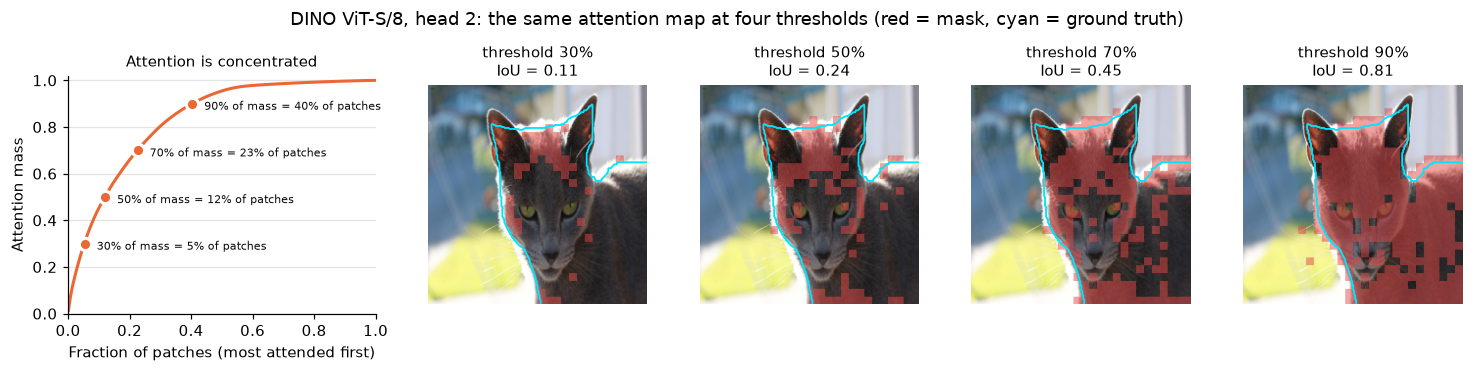

In [6]:
# One test pet and the chosen head; only the attention-mass threshold changes
name = "DINO ViT-S/8"
h = BEST_HEAD[name]
x, fg, ign = get_pet(eval_idx[1])
attn = cls_attention(models[name], x)[:, [h]]        # [1, 1, h, w]
img = to_display(x[0])
demo_thresholds = [0.3, 0.5, 0.7, 0.9]

# Running total of attention mass, patches sorted from most to least attended
a = attn.flatten()
a = a / a.sum()                                      # attention mass sums to 1
cum = a.sort(descending=True).values.cumsum(0).cpu().numpy()
frac_patches = np.arange(1, len(cum) + 1) / len(cum)

fig = plt.figure(figsize=(13.5, 3.4))
grid = fig.add_gridspec(1, 1 + len(demo_thresholds),
                        width_ratios=[1.4] + [1] * len(demo_thresholds))
ax = fig.add_subplot(grid[0])
ax.plot(frac_patches, cum, lw=2, color=COLORS[name])
for i, t in enumerate(demo_thresholds):
    m = attention_to_mask(attn, threshold=t)
    share = m.float().mean().item()                  # fraction of patches in the mask
    ax.plot([share], [t], "o", ms=8, color=COLORS[name], mec="white", mew=2)
    ax.annotate(f"{t:.0%} of mass = {share:.0%} of patches", (share, t),
                xytext=(8, -4), textcoords="offset points", fontsize=7, color="#0b0b0b")
    mask = upsample(m)[0, 0].cpu()
    score = iou(mask, fg, ign).item()
    show(fig.add_subplot(grid[1 + i]), img, mask=mask.numpy(), gt=fg.numpy(),
         title=f"threshold {t:.0%}\nIoU = {score:.2f}")
ax.set_xlabel("Fraction of patches (most attended first)")
ax.set_ylabel("Attention mass")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.yaxis.grid(True); ax.set_axisbelow(True)
ax.set_title("Attention is concentrated")
fig.suptitle(f"{name}, head {h}: the same attention map at four thresholds "
             "(red = mask, cyan = ground truth)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/03b_attention_density.png", bbox_inches="tight")
plt.show()

**Observation:** Attention is very concentrated. For this cat, half of the attention mass sits in just 12% of the patches. At a 30% threshold the mask covers only the top of the head and an ear (IoU 0.11), and it grows steadily with the threshold until it covers most of the cat at 90% (IoU 0.81). That fits the threshold chosen in Section 3: pets fill a large part of each photo, so the mask needs most of the attention mass.

## 5. Test-set results

*Blog: Table 1 and the IoU bar chart (`04_iou_bar.png`).*

Each model uses its chosen head and threshold from Section 3 on the 500 test images. "Same head at 60%" is the paper's threshold. The center-blob baseline predicts a fixed ellipse in the middle of every image.

In [7]:
# test_scores[model][threshold] -> [N_EVAL, heads] per-image, per-head IoU
test_scores = {name: per_head_iou(model, loader, THRESHOLDS)
               for name, model in models.items()}
# chosen[model] -> [N_EVAL] per-image IoU of the chosen head at the chosen threshold
chosen = {n: test_scores[n][BEST_THRESHOLD[n]][:, BEST_HEAD[n]] for n in models}
# at60[model] -> [N_EVAL] per-image IoU of the same head at the paper's 60% threshold
at60 = {n: test_scores[n][0.6][:, BEST_HEAD[n]] for n in models}

# Center-blob baseline: ellipse covering the middle ~50% of the image
yy, xx = torch.meshgrid(torch.linspace(-1, 1, IMG_SIZE), torch.linspace(-1, 1, IMG_SIZE),
                        indexing="ij")
CENTER = ((xx / 0.8) ** 2 + (yy / 0.8) ** 2 <= 1).to(device)

baseline, fg_frac = [], []
for _, tri in loader:
    tri = tri.to(device)
    fg, ign = (tri == 1), (tri == 3)
    fg_frac.append(fg.float().mean((1, 2, 3)).cpu())   # share of pet-interior pixels
    baseline.append(iou(CENTER.expand_as(fg), fg, ign)[:, 0].cpu())
baseline, fg_frac = torch.cat(baseline).numpy(), torch.cat(fg_frac).numpy()

In [8]:
# Blog Table 1 (heads are numbered from 0, as in the figures)
print(f"{'Model':<22}{'Chosen head':>13}{'Test IoU':>10}{'Same head at 60%':>18}"
      f"{'Beats baseline on':>19}")
for n in models:
    n_heads = test_scores[n][BEST_THRESHOLD[n]].shape[1]
    beats = (chosen[n] > baseline).mean()            # share of images beating baseline
    print(f"{n:<22}{f'{BEST_HEAD[n]} of {n_heads}':>13}{chosen[n].mean():>10.2f}"
          f"{at60[n].mean():>18.2f}{beats:>19.0%}")
print(f"{'Center-blob baseline':<22}{'n/a':>13}{baseline.mean():>10.2f}"
      f"{'n/a':>18}{'n/a':>19}")

# Paired comparison on the same images, each model with its chosen head and threshold
win = (chosen["DINO ViT-B/16"] > chosen["Supervised ViT-B/16"]).mean()
print(f"\nDINO ViT-B/16 beats Supervised ViT-B/16 on {win:.0%} of test images")

Model                   Chosen head  Test IoU  Same head at 60%  Beats baseline on
DINO ViT-S/16                1 of 6      0.76              0.50                95%
DINO ViT-S/8                 2 of 6      0.76              0.39                93%
DINO ViT-B/16              10 of 12      0.63              0.32                71%
Supervised ViT-B/16         3 of 12      0.34              0.16                19%
Center-blob baseline            n/a      0.52               n/a                n/a

DINO ViT-B/16 beats Supervised ViT-B/16 on 92% of test images


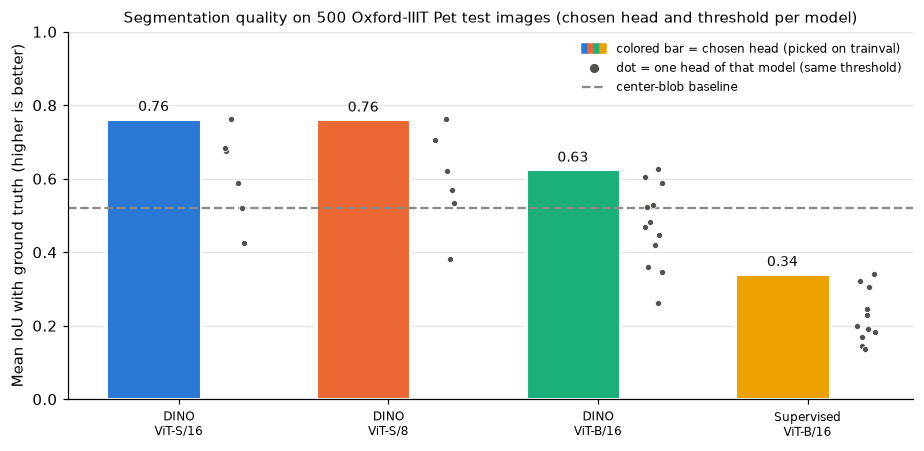

In [9]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.legend_handler import HandlerTuple

names = list(models)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
pos = np.arange(len(names))
vals = [chosen[n].mean() for n in names]
# Bars: chosen head (left of each slot). Dots: every head of that model (right).
bars = ax.bar(pos - 0.12, vals, width=0.45, color=[COLORS[n] for n in names],
              edgecolor="white", linewidth=2)
ax.bar_label(bars, fmt="%.2f", padding=3, color="#0b0b0b", fontsize=9)
jitter = np.random.default_rng(SEED)
for p, n in zip(pos, names):
    hm = test_scores[n][BEST_THRESHOLD[n]].mean(0)  # every head, chosen threshold
    xs = p + 0.27 + jitter.uniform(-0.05, 0.05, len(hm))
    ax.scatter(xs, hm, s=16, color=TEXT_MUTED, edgecolor="white", linewidth=0.5, zorder=3)
ax.axhline(baseline.mean(), ls="--", lw=1.5, color=BASELINE_COLOR, zorder=1)
# Baseline is labeled in the legend so its label never collides with a bar value
bar_handle = tuple(Patch(color=COLORS[n]) for n in names)
dot_handle = Line2D([], [], ls="", marker="o", ms=5, color=TEXT_MUTED)
base_handle = Line2D([], [], ls="--", lw=1.5, color=BASELINE_COLOR)
ax.legend([bar_handle, dot_handle, base_handle],
          ["colored bar = chosen head (picked on trainval)",
           "dot = one head of that model (same threshold)", "center-blob baseline"],
          handler_map={tuple: HandlerTuple(ndivide=None, pad=0)},
          frameon=False, fontsize=8, loc="upper right")
ax.set_xticks(pos, [n.replace(" ", "\n", 1) for n in names], fontsize=8)
ax.set_ylabel("Mean IoU with ground truth (higher is better)")
ax.set_ylim(0, 1); ax.yaxis.grid(True); ax.set_axisbelow(True)
ax.set_title(f"Segmentation quality on {N_EVAL} Oxford-IIIT Pet test images "
             "(chosen head and threshold per model)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/04_iou_bar.png", bbox_inches="tight")
plt.show()

## 6. Where does the attention go?

*Blog: Table 2 and the DINO vs supervised figure (`02_dino_vs_supervised.png`).*

The share of the chosen head's attention mass that lands on the pet, compared with the share of the image the pet covers (what evenly spread attention would give).

In [10]:
@torch.no_grad()
def attention_on_pet(model, head, loader):
    # Share of the chosen head's attention mass on pet-interior pixels, per image
    pet = []
    for x, tri in loader:
        x, tri = x.to(device), tri.to(device)
        # nearest upsampling copies each patch's weight to its pixels; renormalize
        a = upsample(cls_attention(model, x)[:, [head]])
        a = a / a.sum((-2, -1), keepdim=True)
        pet.append((a * (tri == 1)).sum((1, 2, 3)).cpu())
    return torch.cat(pet).numpy()

# Blog Table 2 (test-set means)
print(f"{'Model':<22}{'Attention on the pet':>22}{'Pet share of the image':>24}")
for name, model in models.items():
    pet = attention_on_pet(model, BEST_HEAD[name], loader)
    print(f"{name:<22}{pet.mean():>22.0%}{fg_frac.mean():>24.0%}")

Model                   Attention on the pet  Pet share of the image
DINO ViT-S/16                            70%                     32%
DINO ViT-S/8                             76%                     32%
DINO ViT-B/16                            72%                     32%
Supervised ViT-B/16                      36%                     32%


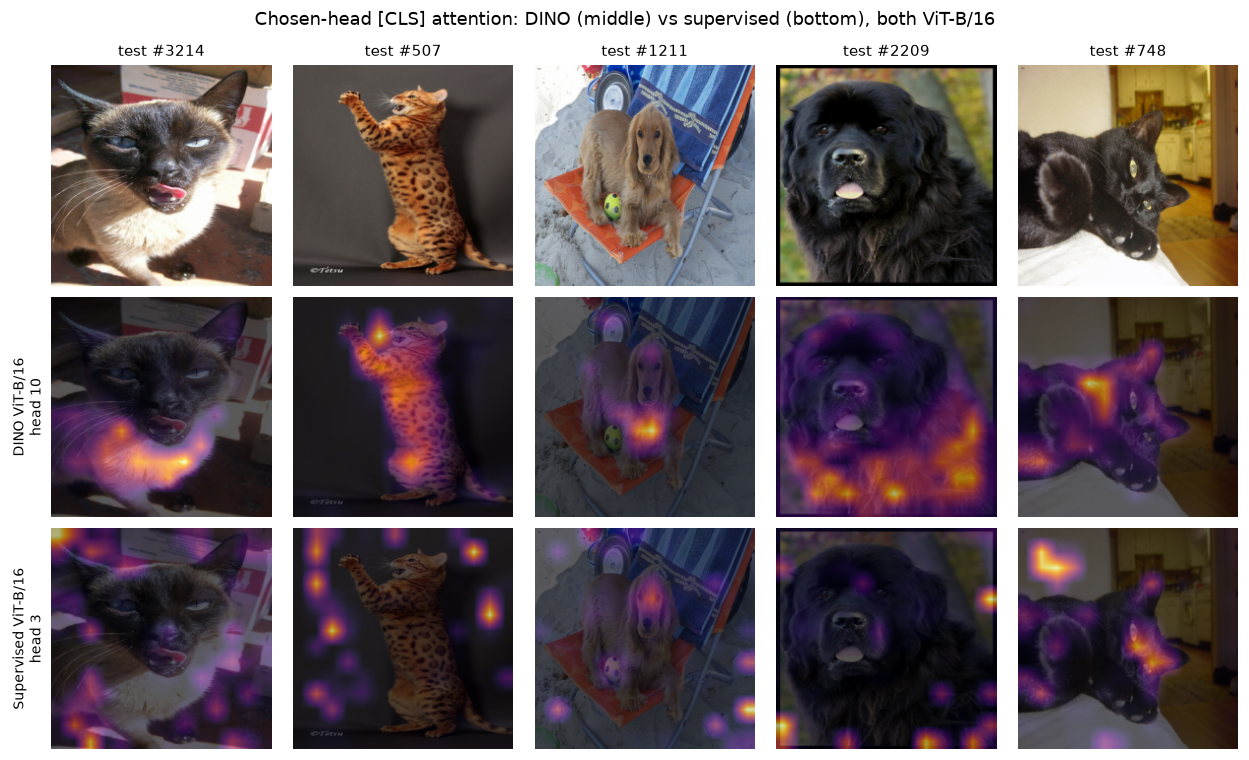

In [11]:
pairs = ["DINO ViT-B/16", "Supervised ViT-B/16"]
idxs = eval_idx[[0, 2, 3, 5, 7]]
fig, axes = plt.subplots(3, len(idxs), figsize=(2.3 * len(idxs), 7))
for col, i in enumerate(idxs):
    x, fg, _ = get_pet(i)
    img = to_display(x[0])
    show(axes[0, col], img, title=f"test #{i}")
    for r, name in enumerate(pairs, start=1):
        a = cls_attention(models[name], x)[0, BEST_HEAD[name]]   # the chosen head only
        show(axes[r, col], img, heatmap=heat(a))
for r, name in enumerate(pairs, start=1):
    row_label(axes[r, 0], f"{name}\nhead {BEST_HEAD[name]}")
fig.suptitle("Chosen-head [CLS] attention: DINO (middle) vs supervised (bottom), "
             "both ViT-B/16")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/02_dino_vs_supervised.png", bbox_inches="tight")
plt.show()

**Observation:** DINO's attention hugs the animal's outline. The supervised model's attention is scattered. A classifier only needs a few discriminative patches to output "cat", so it never has to learn where the whole dog is. DINO on the other hand is forced to learn relationships from scratch without labels, resulting in less noisy maps.

## 7. Where it fails

*Blog: the **Where it fails** paragraph and Table 3.*

The best and worst test images for DINO ViT-S/8 (chosen head and threshold), then mean IoU for small vs large pets (split at the median pet size). Red = predicted mask, cyan = ground-truth outline.

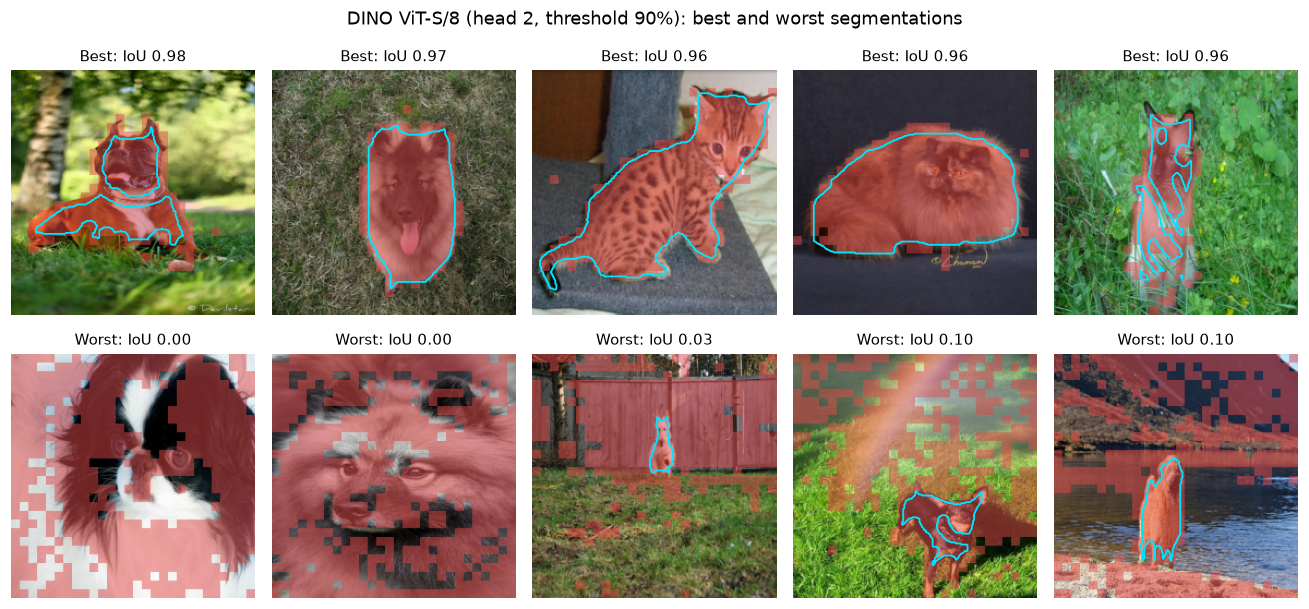

Mean test IoU           Small pets  Large pets  (split at median size)
DINO ViT-S/8                  0.72        0.80
Supervised ViT-B/16           0.31        0.38
Center-blob baseline          0.39        0.65


In [12]:
name = "DINO ViT-S/8"
h, threshold = BEST_HEAD[name], BEST_THRESHOLD[name]
scores = chosen[name]
order = np.argsort(scores)
picks = [("Best", order[::-1][:5]), ("Worst", order[:5])]

fig, axes = plt.subplots(2, 5, figsize=(12, 5.8))
for row, (label, ids) in zip(axes, picks):
    for ax, j in zip(row, ids):
        x, fg, _ = get_pet(eval_idx[j])
        attn = cls_attention(models[name], x)[:, [h]]       # chosen head only
        mask = upsample(attention_to_mask(attn, threshold))[0, 0].cpu().numpy()
        show(ax, to_display(x[0]), mask=mask, gt=fg.numpy(),
             title=f"{label}: IoU {scores[j]:.2f}")
fig.suptitle(f"{name} (head {h}, threshold {threshold:.0%}): "
             "best and worst segmentations")
plt.tight_layout(h_pad=1.5)
plt.savefig(f"{FIG_DIR}/08_failures.png", bbox_inches="tight")
plt.show()

# Blog Table 3: is failure related to how much of the image the pet fills?
# (size = pet-interior fraction, border pixels excluded)
small = fg_frac < np.median(fg_frac)
print(f"{'Mean test IoU':<22}{'Small pets':>12}{'Large pets':>12}"
      "  (split at median size)")
rows = {n: chosen[n] for n in ["DINO ViT-S/8", "Supervised ViT-B/16"]}
rows["Center-blob baseline"] = baseline
for n, s in rows.items():
    print(f"{n:<22}{s[small].mean():>12.2f}{s[~small].mean():>12.2f}")

## 8. Patch features: PCA and k-means

*Blog: **Going one step further: grouping patches** (`07_pca_kmeans.png`).*

This goes beyond the paper's attention-based segmentation: we color each patch by the top 3 PCA components of its feature vector and group the patches with k-means (k = 4).

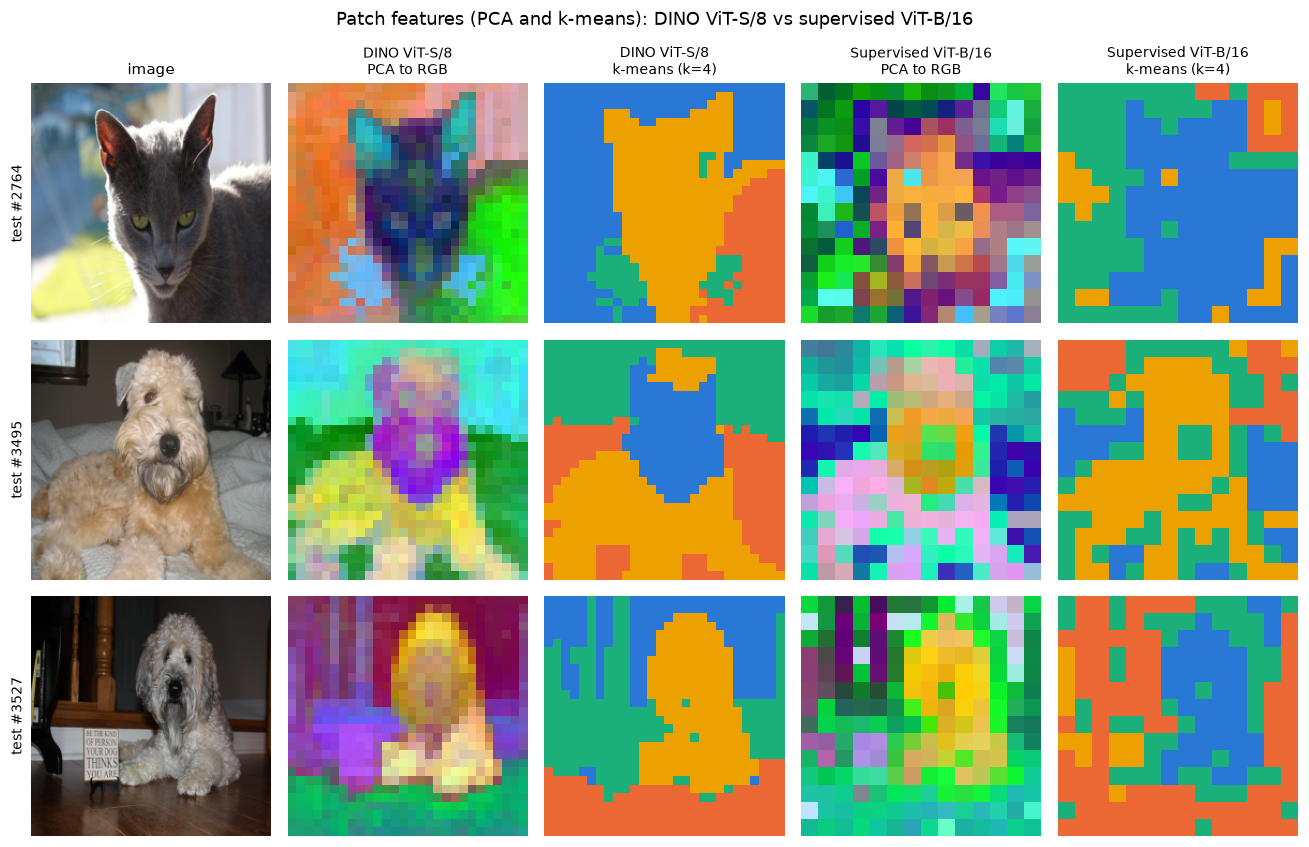

In [13]:
def pca_rgb(f):
    # f: [N, D] patch features -> [N, 3] colors in [0, 1]
    f = f - f.mean(0)
    _, _, V = torch.pca_lowrank(f, q=3)
    p = f @ V[:, :3]
    lo, hi = p.min(0).values, p.max(0).values
    return ((p - lo) / (hi - lo + 1e-8)).cpu().numpy()


def kmeans(f, k=4, iters=50, seed=SEED):
    # Minimal k-means on L2-normalized features; returns a cluster id per row
    f = F.normalize(f, dim=-1)
    g = torch.Generator().manual_seed(seed)
    centers = f[torch.randperm(len(f), generator=g)[:k].to(f.device)].clone()
    for _ in range(iters):
        assign = torch.cdist(f, centers).argmin(1)
        for j in range(k):
            if (assign == j).any():
                centers[j] = f[assign == j].mean(0)
    return assign.cpu().numpy()


CLUSTER_CMAP = ListedColormap(["#2a78d6", "#eb6834", "#1baf7a", "#eda100"])
feat_models = ["DINO ViT-S/8", "Supervised ViT-B/16"]
idxs = eval_idx[[1, 4, 6]]
fig, axes = plt.subplots(len(idxs), 5, figsize=(12, 2.5 * len(idxs) + 0.4))
for row, i in zip(axes, idxs):
    x, fg, _ = get_pet(i)
    show(row[0], to_display(x[0]))
    row_label(row[0], f"test #{i}")
    for j, name in enumerate(feat_models):
        m = models[name]
        side = IMG_SIZE // patch_size(m)
        f = patch_features(m, x)[0]                          # [h*w, D]
        row[1 + 2 * j].imshow(pca_rgb(f).reshape(side, side, 3), interpolation="nearest")
        row[2 + 2 * j].imshow(kmeans(f).reshape(side, side), cmap=CLUSTER_CMAP,
                              interpolation="nearest")
        row[1 + 2 * j].axis("off"); row[2 + 2 * j].axis("off")
# Column titles on the top row only
axes[0, 0].set_title("image")
for j, name in enumerate(feat_models):
    axes[0, 1 + 2 * j].set_title(f"{name}\nPCA to RGB", fontsize=9)
    axes[0, 2 + 2 * j].set_title(f"{name}\nk-means (k=4)", fontsize=9)
fig.suptitle("Patch features (PCA and k-means): DINO ViT-S/8 vs supervised ViT-B/16")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/07_pca_kmeans.png", bbox_inches="tight")
plt.show()

## 9. Summary

*Blog: the **Conclusion**.*

* Without any fine-tuning, thresholding one DINO head's [CLS] attention gives masks that beat the center-blob baseline (Section 5).
* DINO ViT-B/16 clearly beats the supervised ViT-B/16 with the same architecture, and puts far more of its attention on the pet (Sections 5 and 6).
* DINO's patch features, grouped with PCA and k-means, split the image into coherent parts (Section 8).
* Limitations: attention maps show what is important, not what the object is, and the chosen threshold is static such that the approach doesn't generalize as well as we would like.

## AI Disclosure

AI was used to create this notebook based on my own notes and slides from researching the topic. It was also used to scaffold the blog post, although the writing and thoughts are mine.